# Amazon Reviews Sentiment Analysis: Logistic Regression
IT2011 - Artificial Intelligence and Machine Learning, Final Evaluation (Implementation)
Group 2026-Y2-S1-MLB-B11G1-06

**Name / IT Number:** Dissanayaka D.M.N.D.M. / `IT25100100`
**Model:** TF-IDF + Logistic Regression

Contents: data loading, preprocessing and EDA, baseline model, hyperparameter tuning with GridSearchCV, 5-fold cross-validation, evaluation (accuracy, precision, recall, F1, ROC-AUC, confusion matrix), model interpretation and error analysis.

In [1]:
# libraries
import os
import re
import random
from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression


In [2]:
# settings (same in all six notebooks)
SEED = 42
SAMPLE_SIZE = 300000
DATA_PATH = "../data/raw/train.ft.txt"
OUT_DIR = Path("../results/outputs")
FIG_DIR = Path("../results/eda_visualizations")
METRICS_DIR = Path("../results/final_metrics")
for folder in (OUT_DIR, FIG_DIR, METRICS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# stop here if the dataset is missing
assert os.path.exists(DATA_PATH), "train.ft.txt not found in data/raw/"

RANDOM_STATE = SEED
OUTPUT_DIR = OUT_DIR

### Data loading and shared preprocessing
The same steps are used in all six notebooks, so every model is trained and tested on exactly the same reviews:
1. a random sample of 300,000 reviews from `train.ft.txt` (seed 42; the file is sorted, so the first rows would give a biased sample)
2. removing missing values and duplicate reviews
3. text cleaning (lowercase; remove HTML tags, links, numbers and punctuation)
4. removing outliers in review length with the IQR method
5. an 80/20 stratified train/test split (random_state = 42)

Labels: **0 = Negative, 1 = Positive**.

In [3]:
# load a random sample of the reviews
with open(DATA_PATH, "r", encoding="utf-8") as f:
    total_lines = sum(1 for _ in f)

random.seed(SEED)
keep = set(random.sample(range(total_lines), SAMPLE_SIZE))

labels, texts = [], []
with open(DATA_PATH, "r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i in keep:
            tag, _, text = line.strip().partition(" ")
            labels.append(1 if tag == "__label__2" else 0)   # 1 = positive, 0 = negative
            texts.append(text)
df = pd.DataFrame({"label": labels, "text": texts})

# missing values and duplicates
df["text"] = df["text"].replace("", np.nan)
df = df.dropna(subset=["text"]).drop_duplicates(subset="text").reset_index(drop=True)

# text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)             # html tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # links
    text = re.sub(r"[^a-z\s]", " ", text)          # keep letters only
    return re.sub(r"\s+", " ", text).strip()

df["clean_text"] = df["text"].apply(clean_text)
df["word_count"] = df["clean_text"].str.split().str.len()

# outlier removal on review length (IQR method)
q1, q3 = df["word_count"].quantile([0.25, 0.75])
iqr = q3 - q1
df = df[(df["word_count"] >= q1 - 1.5 * iqr) &
        (df["word_count"] <= q3 + 1.5 * iqr)].reset_index(drop=True)

# 80/20 stratified train/test split
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# 5-fold stratified cross-validation and a smaller subset of the training data for tuning
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def dev_subset(data, n=100000):
    subset, _ = train_test_split(data, train_size=n, stratify=data["label"], random_state=SEED)
    return subset.reset_index(drop=True)

print(f"full file: {total_lines:,} reviews | after preprocessing: {len(df):,}")
print(f"train: {len(train_df):,} | test: {len(test_df):,}")
print("positive share (train / test):", round(train_df["label"].mean(), 4), round(test_df["label"].mean(), 4))

full file: 3,600,000 reviews | after preprocessing: 299,983
train: 239,986 | test: 59,997
positive share (train / test): 0.5002 0.5002


In [4]:
print("Training shape:", train_df.shape)
print("Testing shape :", test_df.shape)
display(train_df.head())

print("\nTraining label distribution (0 = Negative, 1 = Positive):")
display(train_df["label"].value_counts().sort_index())

Training shape: (239986, 4)
Testing shape : (59997, 4)


,label,text,clean_text,word_count
0,0,A VERY DRY TEXTBOOK - AND I KNOW THE OTHERS TO...,a very dry textbook and i know the others too ...,120
1,0,"horrible, horrible, horrible!!! need i say mor...",horrible horrible horrible need i say more don...,70
2,1,"Easy Choreography!: I love all of the ""Walk aw...",easy choreography i love all of the walk away ...,121
3,1,One of the BEST books on Vietnam i have ever r...,one of the best books on vietnam i have ever r...,84
4,1,AMAZING ENERGY & GRACE: I've been a big fan of...,amazing energy grace i ve been a big fan of de...,96



Training label distribution (0 = Negative, 1 = Positive):


label
0    119942
1    120044
Name: count, dtype: int64

## Preprocessing & EDA

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            text                                                                                                                                                                                                                                                                                                                                                        

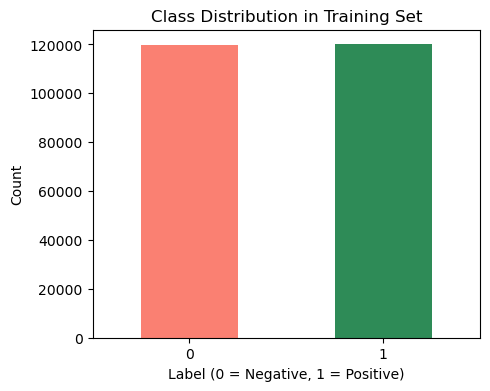

label
1    120044
0    119942
Name: count, dtype: int64


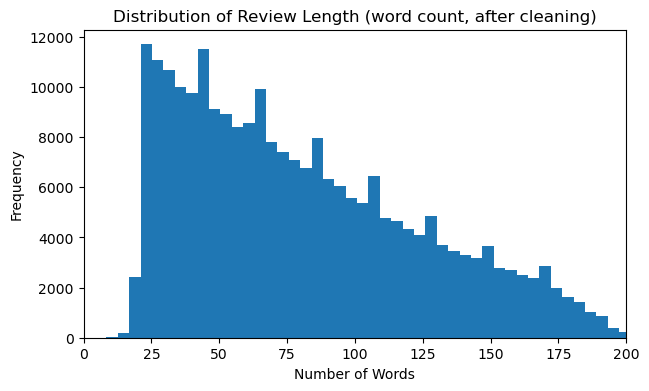

count    239986.000000
mean         80.218409
std          43.946805
min           0.000000
25%          43.000000
50%          71.000000
75%         110.000000
max         210.000000
Name: word_count, dtype: float64


In [5]:
# text cleaning was already done in the shared preprocessing
print(train_df[["text", "clean_text"]].head(3).to_string())

# ---- EDA 1: Class balance ----
plt.figure(figsize=(5, 4))
train_df["label"].value_counts().sort_index().plot(kind="bar", color=["salmon", "seagreen"])
plt.title("Class Distribution in Training Set")
plt.xlabel("Label (0 = Negative, 1 = Positive)")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

print(train_df["label"].value_counts())

# ---- EDA 2: Review length distribution ----
plt.figure(figsize=(7, 4))
plt.hist(train_df["word_count"], bins=50)
plt.title("Distribution of Review Length (word count, after cleaning)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.xlim(0, 200)
plt.show()

print(train_df["word_count"].describe())

### Preprocessing techniques

#### 1. Missing Values & Duplicate Removal

Missing values per column:
label         0
text          0
clean_text    0
word_count    0
dtype: int64

Dropped 0 rows with missing text
Duplicate reviews found: 0
Dropped 0 duplicate rows
Rows remaining: 239986


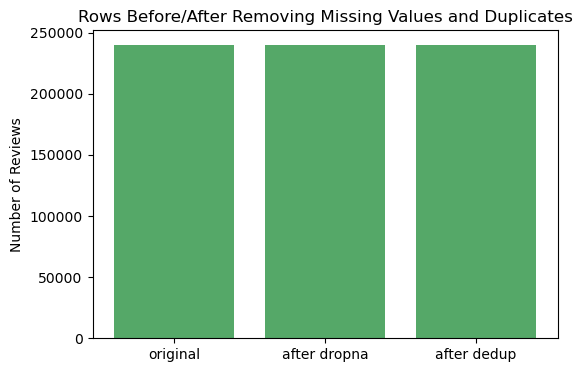

In [6]:
rows_start = len(train_df)

# an empty string is not caught by isnull(), so convert it first
train_df["text"] = train_df["text"].replace("", np.nan)
print("Missing values per column:")
print(train_df.isnull().sum())

train_df = train_df.dropna(subset=["text"]).reset_index(drop=True)
rows_after_na = len(train_df)
print(f"\nDropped {rows_start - rows_after_na} rows with missing text")

dupes = train_df.duplicated(subset="text").sum()
print(f"Duplicate reviews found: {dupes}")
train_df = train_df.drop_duplicates(subset="text").reset_index(drop=True)
rows_after_dedup = len(train_df)
print(f"Dropped {rows_after_na - rows_after_dedup} duplicate rows")
print(f"Rows remaining: {rows_after_dedup}")

plt.figure(figsize=(6, 4))
plt.bar(["original", "after dropna", "after dedup"],
        [rows_start, rows_after_na, rows_after_dedup], color="#55A868")
plt.title("Rows Before/After Removing Missing Values and Duplicates")
plt.ylabel("Number of Reviews")
plt.show()

# the shared preprocessing already removed these, so no rows should be dropped here
assert len(train_df) == 239_986, "training set changed - it must stay identical to the shared split"


#### 2. Outlier Removal (IQR method on review length)



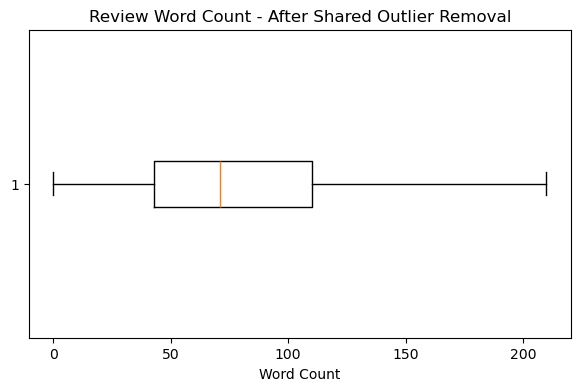

IQR bounds: [-57.5, 210.5] words
IQR outlier removal was applied once to the whole 300,000-review sample in the shared
preprocessing (17 rows removed). Rows are not removed again here, so the training set
stays identical for all six models. Rows outside these bounds now: 0


In [7]:
plt.figure(figsize=(7, 4))
plt.boxplot(train_df["word_count"], orientation="horizontal")
plt.title("Review Word Count - After Shared Outlier Removal")
plt.xlabel("Word Count")
plt.show()

Q1 = train_df["word_count"].quantile(0.25)
Q3 = train_df["word_count"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outside = ((train_df["word_count"] < lower_bound) | (train_df["word_count"] > upper_bound)).sum()
print(f"IQR bounds: [{lower_bound:.1f}, {upper_bound:.1f}] words")
print("IQR outlier removal was applied once to the whole 300,000-review sample in the shared")
print("preprocessing (17 rows removed). Rows are not removed again here, so the training set")
print(f"stays identical for all six models. Rows outside these bounds now: {outside}")

#### 3. Encoding a Categorical Variable (review length category)



,word_count,length_category,length_short,length_medium,length_long
0,120,long,False,False,True
1,70,medium,False,True,False
2,121,long,False,False,True
3,84,medium,False,True,False
4,96,long,False,False,True


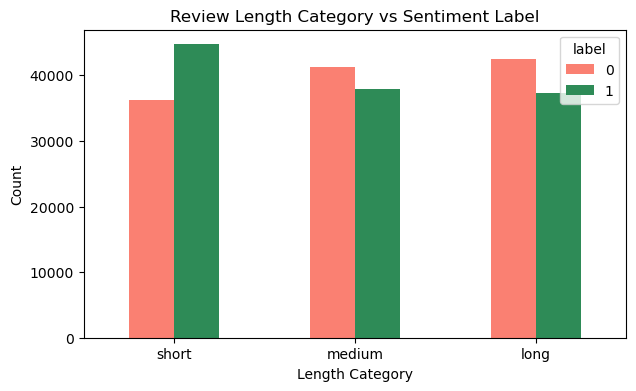

In [8]:
train_df["length_category"] = pd.qcut(
    train_df["word_count"], q=3, labels=["short", "medium", "long"]
)
length_dummies = pd.get_dummies(train_df["length_category"], prefix="length")
train_df = pd.concat([train_df, length_dummies], axis=1)

display(train_df[["word_count", "length_category"] + list(length_dummies.columns)].head())

ct = pd.crosstab(train_df["length_category"], train_df["label"])
ct.plot(kind="bar", figsize=(7, 4), color=["salmon", "seagreen"])
plt.title("Review Length Category vs Sentiment Label")
plt.xlabel("Length Category")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(title="label")
plt.show()


#### 4. Normalization / Scaling



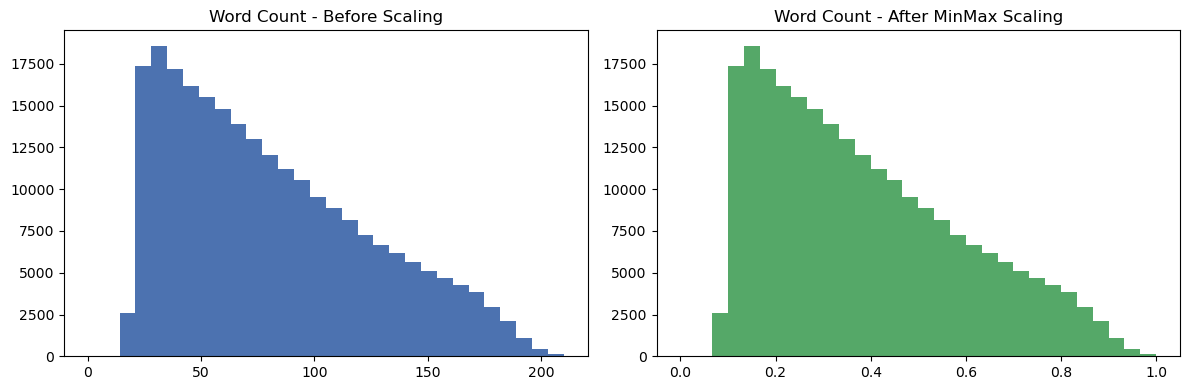

,word_count,word_count_scaled
count,239986.000000,239986.000000
mean,80.218409,0.381992
std,43.946805,0.209270
min,0.000000,0.000000
25%,43.000000,0.204762
50%,71.000000,0.338095
75%,110.000000,0.523810
max,210.000000,1.000000


In [9]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
train_df["word_count_scaled"] = scaler.fit_transform(train_df[["word_count"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_df["word_count"], bins=30, color="#4C72B0")
axes[0].set_title("Word Count - Before Scaling")
axes[1].hist(train_df["word_count_scaled"], bins=30, color="#55A868")
axes[1].set_title("Word Count - After MinMax Scaling")
plt.tight_layout()
plt.show()

display(train_df[["word_count", "word_count_scaled"]].describe())


#### 5. Tokenization & Stop-word Removal (experiment)



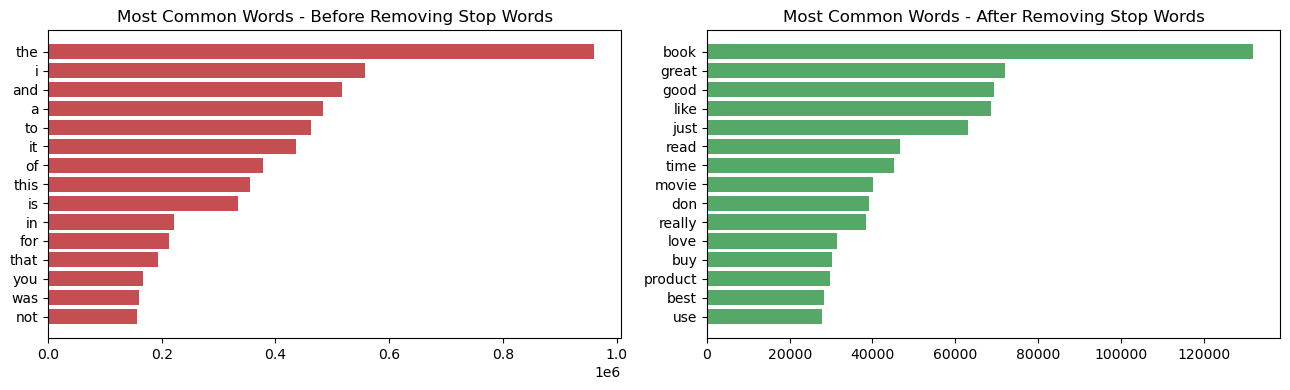

clean_text: mean CV F1 = 0.8777 (+/- 0.0032)
processed_text: mean CV F1 = 0.8585 (+/- 0.0055)


,text_column,mean_cv_f1,std
0,clean_text,0.8777,0.0032
1,processed_text,0.8585,0.0055



-> Based on this result, the main pipeline below keeps stop words (uses clean_text, not processed_text).


In [10]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import cross_val_score

tokens = train_df["clean_text"].str.split()
tokens_no_stop = tokens.apply(lambda words: [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2])
train_df["processed_text"] = tokens_no_stop.apply(lambda words: " ".join(words))

def most_common_words(token_lists, n=15):
    counts = Counter()
    for toks in token_lists:
        counts.update(toks)
    return counts.most_common(n)

before_words = most_common_words(tokens)
after_words = most_common_words(tokens_no_stop)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh([w for w, _ in before_words][::-1], [c for _, c in before_words][::-1], color="#C44E52")
axes[0].set_title("Most Common Words - Before Removing Stop Words")
axes[1].barh([w for w, _ in after_words][::-1], [c for _, c in after_words][::-1], color="#55A868")
axes[1].set_title("Most Common Words - After Removing Stop Words")
plt.tight_layout()
plt.show()

# quick test: does removing stop words help this model? (15,000 reviews)
exp_sample = train_df.sample(n=min(15000, len(train_df)), random_state=RANDOM_STATE)
exp_cv = CV   # 5-fold stratified CV

exp_rows = []
for col in ["clean_text", "processed_text"]:
    exp_pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])
    scores = cross_val_score(exp_pipe, exp_sample[col], exp_sample["label"], cv=exp_cv, scoring="f1_weighted")
    exp_rows.append({"text_column": col, "mean_cv_f1": round(scores.mean(), 4), "std": round(scores.std(), 4)})
    print(f"{col}: mean CV F1 = {scores.mean():.4f} (+/- {scores.std():.4f})")

exp_df = pd.DataFrame(exp_rows)
display(exp_df)
print("\n-> Based on this result, the main pipeline below keeps stop words "
      "(uses clean_text, not processed_text).")


In [11]:
# prepare X and y
X_train = train_df["clean_text"].values
y_train = train_df["label"].values

X_test = test_df["clean_text"].values
y_test = test_df["label"].values


# 100,000-review subset of the training data for tuning
dev = dev_subset(train_df)
X_dev, y_dev = dev["clean_text"].values, dev["label"].values
print("train:", len(X_train), "| test:", len(X_test), "| dev subset:", len(X_dev))

train: 239986 | test: 59997 | dev subset: 100000


## Model 1 – Baseline

**Algorithm:** TF-IDF + Logistic Regression

TF-IDF converts the review text into numerical features. The classifier then learns to separate the two labels.


In [12]:
# baseline model
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 1),
        min_df=2,
        max_features=50000
    )),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

start = time.time()
baseline.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.2f} seconds")


Training time: 17.25 seconds


In [13]:
# evaluation function
def evaluate(model, X, y, name):
    pred = model.predict(X)

    accuracy = accuracy_score(y, pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y, pred, average="weighted", zero_division=0
    )

    print("=" * 60)
    print(name)
    print("=" * 60)
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y, pred, zero_division=0))

    cm = confusion_matrix(y, pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=sorted(np.unique(y))
    )
    disp.plot()
    plt.title(name)
    plt.tight_layout()
    plt.show()

    return {
        "model": name,
        "accuracy": accuracy,
        "precision_weighted": precision,
        "recall_weighted": recall,
        "f1_weighted": f1
    }


Model 1 - Baseline
Accuracy : 0.9022
Precision: 0.9022
Recall   : 0.9022
F1-score : 0.9022

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90     29986
           1       0.90      0.90      0.90     30011

    accuracy                           0.90     59997
   macro avg       0.90      0.90      0.90     59997
weighted avg       0.90      0.90      0.90     59997



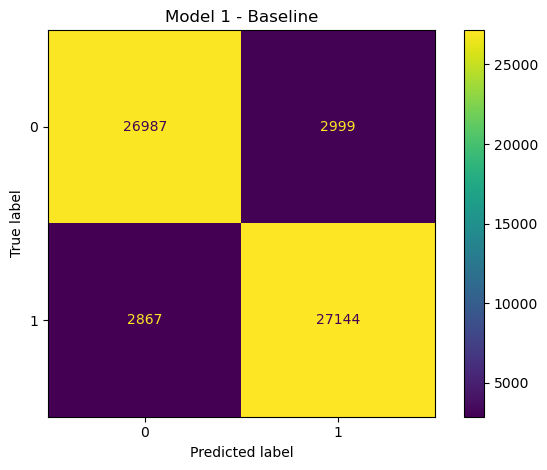

In [14]:
# baseline results
results = []

baseline_result = evaluate(
    baseline,
    X_test,
    y_test,
    "Model 1 - Baseline"
)
results.append(baseline_result)


## Hyperparameter tuning

GridSearchCV tries 12 parameter combinations on the 100,000-review development subset with the shared 5-fold stratified cross-validation, and selects the configuration with the highest F1-score (same procedure as the SVM notebook).

In [15]:
# gridSearchCV

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, min_df=2)),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__sublinear_tf": [False, True],
    "classifier__C": [0.5, 1.0, 2.0]
}

grid = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=CV,
    n_jobs=-1,
    verbose=1
)

start = time.time()
grid.fit(X_dev, y_dev)

print(f"GridSearch time: {time.time() - start:.2f} seconds")
print("\nBest parameters:")
print(grid.best_params_)
print(f"Best CV F1: {grid.best_score_:.4f}")


Fitting 5 folds for each of 12 candidates, totalling 60 fits
GridSearch time: 112.85 seconds

Best parameters:
{'classifier__C': 2.0, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Best CV F1: 0.9159


Training time: 34.6 s
Tuned / GridSearch Best Model
Accuracy : 0.9242
Precision: 0.9242
Recall   : 0.9242
F1-score : 0.9242

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.92      0.92     29986
           1       0.92      0.92      0.92     30011

    accuracy                           0.92     59997
   macro avg       0.92      0.92      0.92     59997
weighted avg       0.92      0.92      0.92     59997



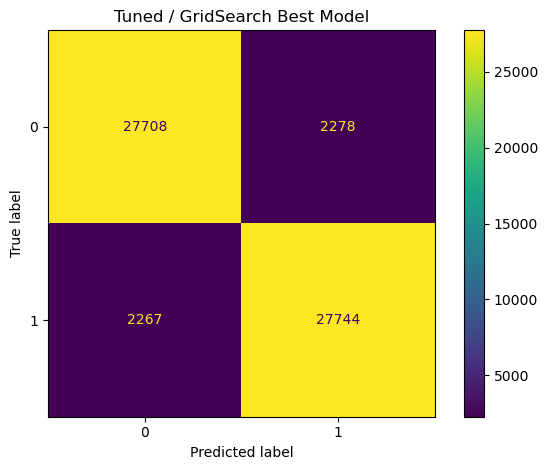

In [16]:
# refit best configuration on selected training data
best_model = grid.best_estimator_
start = time.time()
best_model.fit(X_train, y_train)
lr_train_time = round(time.time() - start, 1)
print(f"Training time: {lr_train_time} s")

best_result = evaluate(
    best_model,
    X_test,
    y_test,
    "Tuned / GridSearch Best Model"
)
best_result["best_params"] = str(grid.best_params_)
best_result["best_cv_f1"] = float(grid.best_score_)
results.append(best_result)


## K-Fold Cross-Validation
The tuned model is checked with the shared 5-fold stratified CV on the 100,000-review development subset.

F1 scores for each fold: [0.9153 0.9166 0.9163 0.9155 0.916 ]
Mean F1: 0.9159  |  Std Dev: 0.0005


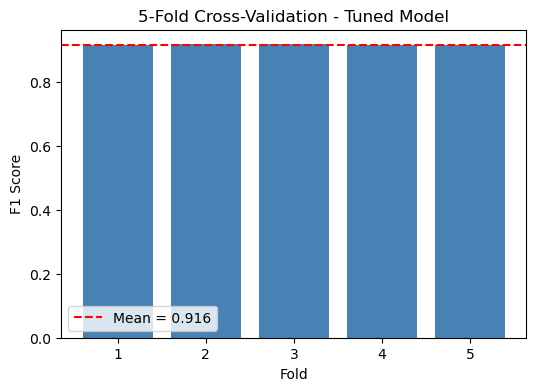

In [17]:
from sklearn.model_selection import cross_val_score

skf = CV   # 5-fold stratified CV
cv_scores = cross_val_score(best_model, X_dev, y_dev, cv=skf, scoring="f1", n_jobs=-1)

print("F1 scores for each fold:", np.round(cv_scores, 4))
print(f"Mean F1: {cv_scores.mean():.4f}  |  Std Dev: {cv_scores.std():.4f}")

plt.figure(figsize=(6, 4))
plt.bar(range(1, len(cv_scores) + 1), cv_scores, color="steelblue")
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean = {cv_scores.mean():.3f}")
plt.xlabel("Fold")
plt.ylabel("F1 Score")
plt.title("5-Fold Cross-Validation - Tuned Model")
plt.legend()
plt.show()


## Model Interpretation & Error Analysis 



Top words pushing toward label 0 (Negative):
       feature  weight
 disappointing -21.056
          poor -20.813
           not -20.664
        boring -19.931
         worst -19.282
  disappointed -16.955
      terrible -16.732
disappointment -16.663
      horrible -16.455
         waste -15.889
     not worth -15.611
         awful -13.921
        poorly -13.603
     the worst -12.977
 unfortunately -12.870

Top words pushing toward label 1 (Positive):
    feature  weight
  excellent  21.375
      great  21.099
    awesome  16.384
  wonderful  14.512
    perfect  14.192
    amazing  13.894
  fantastic  11.208
        fun  11.062
       good  10.745
better than  10.646
    not bad  10.472
     highly  10.237
      loves  10.039
  beautiful   9.444
  love this   9.426


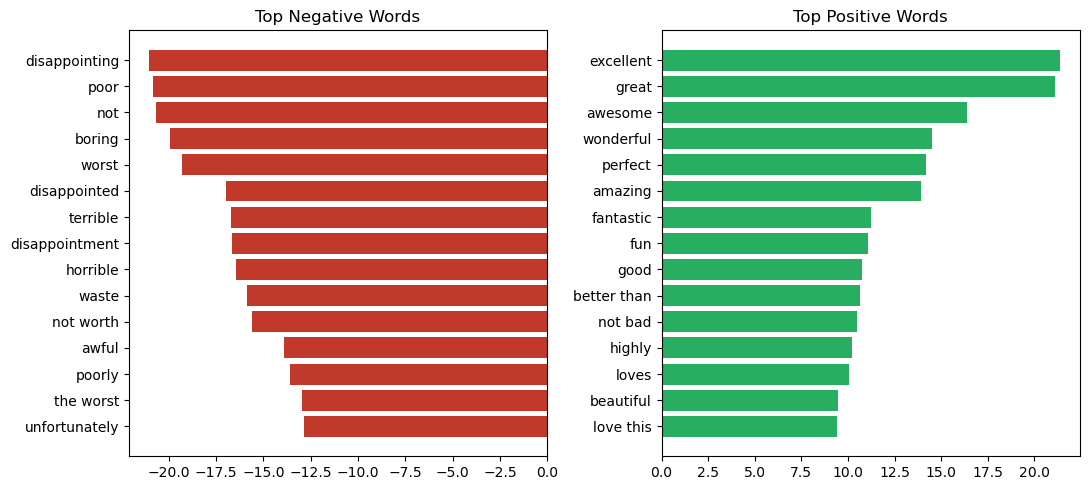


ROC AUC: 0.9764


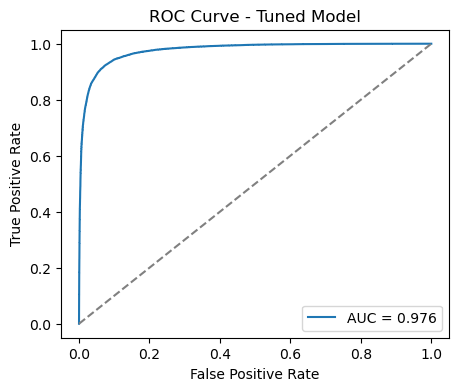


Total errors: 4545 of 59997

Error rate by review length:
                 mean   sum  count
length_bucket                     
short          0.0651   464   7126
medium         0.0706  1894  26822
long           0.0840  2187  26049

Most confident mistakes:

True=1  Pred=0  Confidence=0.500
bad set the next to last dvd didn t work at all and now i have to wait forever to get another set poor quality is not good business

True=0  Pred=1  Confidence=0.500
outstanding device wonderful reading device easy to use and easy to download books my daughter loves to read and loves using her kindle

True=0  Pred=1  Confidence=0.500
t great and very interesting book that i ever read since many years this book is the most important gift of my life

True=0  Pred=1  Confidence=0.499
another great book from joann mapson joann writes great stories with believeable characters people you know or want to know her stories are hard to put down you can feel their pain and their joy and her endings leave you

In [18]:
from sklearn.metrics import roc_auc_score, roc_curve

# ---- Top positive/negative words (model coefficients) ----
tfidf_fit = best_model.named_steps["tfidf"]
clf_fit = best_model.named_steps["classifier"]
feature_names = np.array(tfidf_fit.get_feature_names_out())
coefs = clf_fit.coef_[0]
order = np.argsort(coefs)

top_negative = pd.DataFrame({"feature": feature_names[order[:15]], "weight": coefs[order[:15]]})
top_positive = pd.DataFrame({"feature": feature_names[order[-15:][::-1]], "weight": coefs[order[-15:][::-1]]})

print("Top words pushing toward label 0 (Negative):")
print(top_negative.round(3).to_string(index=False))
print("\nTop words pushing toward label 1 (Positive):")
print(top_positive.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(top_negative["feature"][::-1], top_negative["weight"][::-1], color="#c0392b")
axes[0].set_title("Top Negative Words")
axes[1].barh(top_positive["feature"][::-1], top_positive["weight"][::-1], color="#27ae60")
axes[1].set_title("Top Positive Words")
plt.tight_layout()
plt.show()

# ---- ROC-AUC ----
y_test_binary = y_test   # labels are already 0 = Negative, 1 = Positive
test_probs = best_model.predict_proba(X_test)[:, 1]   # P(label == 1)
auc_score = roc_auc_score(y_test_binary, test_probs)
print(f"\nROC AUC: {auc_score:.4f}")

fpr, tpr, _ = roc_curve(y_test_binary, test_probs)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Model")
plt.legend()
plt.show()

best_result["roc_auc"] = float(auc_score)

# ---- Error analysis by review length ----
test_word_count = pd.Series(X_test).str.split().str.len()
test_pred = best_model.predict(X_test)

error_df = pd.DataFrame({
    "true": y_test,
    "pred": test_pred,
    "score": test_probs,
    "word_count": test_word_count.values,
    "text": X_test,
})
error_df["wrong"] = error_df["true"] != error_df["pred"]
error_df["length_bucket"] = pd.cut(
    error_df["word_count"], bins=[0, 30, 80, 10_000], labels=["short", "medium", "long"]
)

print("\nTotal errors:", error_df["wrong"].sum(), "of", len(error_df))
print("\nError rate by review length:")
print(error_df.groupby("length_bucket", observed=True)["wrong"].agg(["mean", "sum", "count"]).round(4))

wrong_df = error_df[error_df["wrong"]].copy()
wrong_df["confidence"] = (wrong_df["score"] - 0.5).abs()
print("\nMost confident mistakes:")
for _, r in wrong_df.sort_values("confidence", ascending=False).head(5).iterrows():
    print(f"\nTrue={r['true']}  Pred={r['pred']}  Confidence={r['confidence']:.3f}")
    print(str(r["text"])[:250])


In [19]:
# compare varieties
comparison = pd.DataFrame(results)
display(comparison)

comparison.to_csv(OUTPUT_DIR / "lr_model_comparison.csv", index=False)
print("Saved:", OUTPUT_DIR / "lr_model_comparison.csv")


,model,accuracy,precision_weighted,recall_weighted,f1_weighted,best_params,best_cv_f1,roc_auc
0,Model 1 - Baseline,0.902228,0.902236,0.902228,0.902228,NaN,NaN,NaN
1,Tuned / GridSearch Best Model,0.924246,0.924246,0.924246,0.924246,"{'classifier__C': 2.0, 'tfidf__ngram_range': (...",0.915933,0.976433


Saved: ..\results\outputs\lr_model_comparison.csv


In [20]:
# save the trained model
model_path = OUTPUT_DIR / "lr_best_model.joblib"
joblib.dump(best_model, model_path)

print("Saved best model to:", model_path)


Saved best model to: ..\results\outputs\lr_best_model.joblib


In [21]:
# test a few new reviews
example_reviews = [
    "I really love this product. It is excellent.",
    "Very disappointed. The product was terrible."
]

predictions = best_model.predict(example_reviews)

for review, pred in zip(example_reviews, predictions):
    print("Review:", review)
    print("Predicted label:", pred, "(Positive)" if pred == 1 else "(Negative)")
    print()


Review: I really love this product. It is excellent.
Predicted label: 1 (Positive)

Review: Very disappointed. The product was terrible.
Predicted label: 0 (Negative)



In [22]:
# save the final result for the group comparison (same format in all six notebooks)
tn, fp, fn, tp = confusion_matrix(y_test, best_model.predict(X_test)).ravel()
result = {
    "model": "Logistic Regression", "student_id": "IT25100100",
    "accuracy": round(accuracy_score(y_test, best_model.predict(X_test)), 4),
    "precision": round(precision_score(y_test, best_model.predict(X_test)), 4),
    "recall": round(recall_score(y_test, best_model.predict(X_test)), 4),
    "f1": round(f1_score(y_test, best_model.predict(X_test)), 4),
    "f1_macro": round(f1_score(y_test, best_model.predict(X_test), average="macro"), 4),
    "roc_auc": round(roc_auc_score(y_test, test_probs), 4),
    "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    "cv_f1_mean": round(grid.best_score_, 4),
    "cv_f1_std": round(grid.cv_results_["std_test_score"][grid.best_index_], 4),
    "train_time_s": lr_train_time, "n_train": len(X_train),
    "best_params": str(grid.best_params_), "notes": "Tuned on 100k dev subset with 5-fold CV",
}
pd.DataFrame([result]).to_csv(os.path.join(METRICS_DIR, "Logistic_Regression.csv"), index=False)
print("Saved:", os.path.join(METRICS_DIR, "Logistic_Regression.csv"))

Saved: ..\results\final_metrics\Logistic_Regression.csv


## Conclusion

Logistic Regression with TF-IDF was trained on the shared sample (239,986 training and 59,997 test reviews).

- **Tuning:** the baseline (unigrams, C = 1.0) reached accuracy 0.9022. GridSearchCV selected C = 2.0, unigrams + bigrams and `sublinear_tf=True` (CV F1 0.9159 ± 0.0005). The tuned model reached accuracy 0.9242, F1 0.9243 and ROC-AUC 0.9764 on the test set, which is 2.20 points above the baseline.
- **Preprocessing:** the stop-word experiment showed that keeping stop words is better (CV F1 0.8777 vs 0.8585), because words such as "not" carry sentiment.
- **Interpretation:** the largest coefficients are clear sentiment words ("excellent" and "great" for positive; "disappointing", "poor" and "not" for negative), so the model is easy to explain.
- **Errors:** the error rate increases with review length (6.51 % short, 7.06 % medium, 8.40 % long), because long reviews often mix praise and complaints.

**Limitations:** the model is linear and uses bag-of-words features, so it cannot handle sarcasm or mixed reviews well, and some mistakes come from noisy labels. Its F1 is 0.67 points below the Linear SVM (0.9243 vs 0.9310).